# Chapter 2: Sentence embeddings and personality items

**Theory 10 min, exercise 30 min.**

Chapter 1 embedded single words with a shallow network. Real texts are sentences, and the model that embeds them is a **transformer**. This chapter explains just enough of the transformer to understand what a *sentence* embedding is, then puts it to work on something psychologists care about: whether a model's notion of similarity matches what people do when they answer a personality questionnaire.

## Theory

### From words to sentences: the transformer

![The transformer architecture](images/transformer.png)

A transformer has three stages. A **tokenizer** splits the text into pieces and looks each one up in an embedding table, exactly like Chapter 1. A stack of **attention** blocks then mixes information between the pieces, so that the vector for each word comes to depend on the words around it. Finally a **model head** turns the mixed vectors into whatever the model was trained to output. For feature extraction we stop before the head and read out the vectors.

### Tokenization

![A sentence is split into tokens, with special markers at the start and end](images/tokenization.png)

The tokenizer does not work on whole words. It has a fixed vocabulary of about 30,000 **sub-word tokens** learned from frequency statistics. Common words are single tokens; rare words, numbers and typos are broken into pieces.

![Rare strings are broken into sub-word pieces](images/tokenization_numbers.png)

This matters in practice. A model never sees *"202000"*, it sees *2020* followed by *##00*. Questionnaire items with unusual words, abbreviations or domain jargon get fragmented, and the model has to reconstruct their meaning from the pieces.

### Attention: context changes the vector

![An attention head computes, for every token, a weighted mixture of all the other tokens](images/attention.png)

Attention is what makes a transformer different from word2vec. For every token, the model computes how relevant every other token in the sentence is (the attention matrix), then updates the token's vector as a weighted mixture of the others. Several such **heads** run in parallel and the block is repeated many times. The result is a **contextualised embedding**: the vector for *bank* in *river bank* ends up different from the vector for *bank* in *bank account*. You do not need the details of queries, keys and values for this tutorial, only the consequence: a token's vector depends on its sentence.

### Training without labels: masked language modeling

![Masked language modeling: hide a token and predict it from the rest](images/mlm.png)

Where does the training signal come from? Models in the BERT family are trained by **masked language modeling**: hide a random token, and ask the model to predict it from the rest of the sentence. Predicting *it* in *"This was [MASK], the descent"* requires understanding grammar and meaning, and the network learns both from raw text alone. No human labels are involved, which is why these models can be trained on billions of sentences.

### One vector per sentence: CLS or pooling

After the attention stack we have one vector per token, but we want one vector per sentence. There are two conventions.

![The CLS approach keeps the vector of the special first token](images/cls.png)

The **CLS approach** keeps only the vector of the special `[CLS]` token at the start. Because attention lets that token look at everything, it can learn to summarise the sentence.

![The pooling approach averages the token vectors](images/pooling.png)

The **pooling approach** averages the vectors of all tokens. It is simpler, and it is what the `sentence-transformers` models you will use do. Those models have an extra training step: pairs of sentences known to be paraphrases are pushed together and unrelated pairs pushed apart, so that cosine similarity between pooled vectors becomes a good measure of meaning similarity (Reimers and Gurevych, 2019).

### Why psychologists should care: items are text

![Personality items with their factor and construct labels](images/exercise_items.png)

Every questionnaire item is a short text. Psychometrics has always treated the item text as something to be read by participants and otherwise ignored, with structure inferred only from response patterns. Embeddings let us treat the text itself as data.

Wulff and Mata (2025) embedded thousands of items from personality inventories and found that the semantic similarity between two items predicts the empirical correlation between them surprisingly well, that constructs with different names often sit in the same region of embedding space, and that constructs with the same name sometimes do not. They call this *taxonomic incommensurability*: the names on our scales are not a reliable guide to what they measure.

The exercise reproduces the core of that analysis on 300 items from the IPIP-NEO, with a general-purpose model first and a model fine-tuned on personality items second.

```{admonition} Check your understanding
:class: note
1. Why does the same word get different vectors in different sentences in a transformer but not in word2vec?
2. What is the training signal for masked language modeling, and why does it need no human annotation?
3. If you averaged the Chapter 1 word vectors of all words in a sentence, how would that differ from a sentence-transformer embedding?
```

## Exercise

Press the rocket at the top of the page and choose **Colab**, then run the cells in order.

### Setup

Installs `sentence-transformers` and `pacmap` on Colab and loads the embedding model. About a minute.

```{admonition} In the session and after it
:class: tip
Sections marked **Optional** will not fit into the live session. They are there for afterwards, and they run on the same Colab copy.
```

In [1]:
import sys
if 'google.colab' in sys.modules:
    !pip install -q sentence-transformers pacmap

import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.metrics.pairwise import cosine_similarity
from sentence_transformers import SentenceTransformer

# Data is read straight from the public course repository; nothing to upload or mount.
DATA = "https://raw.githubusercontent.com/dwulff/LLM4BeSci_2025MetaRep/main/day_2/"

# The embedding model used in this chapter. 22M parameters, 384 dimensions, fast on a CPU.
MODEL_NAME = "all-MiniLM-L6-v2"

model = SentenceTransformer(MODEL_NAME)
print("Loaded", MODEL_NAME, "with", model.get_sentence_embedding_dimension(), "dimensions")

Loaded all-MiniLM-L6-v2 with 384 dimensions


### 2.1 The items

300 items from the IPIP-NEO personality inventory with three columns:

- `factor`: the Big Five factor (Neuroticism, Extraversion, ...)
- `construct`: the facet within that factor (Anxiety, Friendliness, ...)
- `item`: the item text that participants rate

In [2]:
personality = pd.read_csv(DATA + "items.csv")
print(personality["factor"].value_counts().to_string())
personality

factor
Conscientiousness    60
Extraversion         60
Openness             60
Agreeableness        60
Neuroticism          60


,factor,construct,item
0,Conscientiousness,Achievement-Striving,Go straight for the goal.
1,Conscientiousness,Achievement-Striving,Plunge into tasks with all my heart.
2,Conscientiousness,Achievement-Striving,Demand quality.
3,Conscientiousness,Achievement-Striving,Set high standards for myself and others.
4,Conscientiousness,Achievement-Striving,Turn plans into actions.
...,...,...,...
295,Neuroticism,Vulnerability,Remain calm under pressure.
296,Neuroticism,Vulnerability,Am calm even in tense situations.
297,Neuroticism,Vulnerability,Can handle complex problems.
298,Neuroticism,Vulnerability,Readily overcome setbacks.


### 2.2 Embed the items and compute their similarities

We embed all 300 items in one call and compute the 300 x 300 cosine similarity matrix.

In [3]:
item_features = pd.DataFrame(model.encode(personality["item"]), index=personality["item"])

predicted_sims = pd.DataFrame(
    cosine_similarity(item_features),
    index=personality["item"], columns=personality["item"]
)
predicted_sims.round(2)

item,Go straight for the goal.,Plunge into tasks with all my heart.,Demand quality.,Set high standards for myself and others.,Turn plans into actions.,Do more than what's expected of me.,Work hard.,Do just enough work to get by.,Am not highly motivated to succeed.,Put little time and effort into my work.,...,Panic easily.,Get overwhelmed by emotions.,Feel that I'm unable to deal with things.,Can't make up my mind.,Become overwhelmed by events.,Remain calm under pressure.,Am calm even in tense situations.,Can handle complex problems.,Readily overcome setbacks.,Know how to cope.
item,,,,,,,,,,,,,,,,,,,,,
Go straight for the goal.,1.00,0.25,0.12,0.14,0.24,0.24,0.24,0.24,0.20,0.12,...,0.20,0.14,0.03,0.07,0.14,0.25,0.15,0.10,0.13,0.13
Plunge into tasks with all my heart.,0.25,1.00,0.09,0.28,0.44,0.41,0.40,0.47,0.41,0.39,...,0.33,0.51,0.45,0.21,0.55,0.37,0.21,0.30,0.25,0.32
Demand quality.,0.12,0.09,1.00,0.25,0.17,0.10,0.26,0.12,0.15,0.21,...,0.03,0.11,0.03,0.05,0.12,0.19,0.04,0.31,0.22,0.11
Set high standards for myself and others.,0.14,0.28,0.25,1.00,0.25,0.37,0.29,0.20,0.26,0.27,...,0.05,0.26,0.27,0.05,0.28,0.30,0.20,0.25,0.40,0.32
Turn plans into actions.,0.24,0.44,0.17,0.25,1.00,0.39,0.28,0.37,0.22,0.31,...,0.27,0.29,0.23,0.20,0.38,0.25,0.19,0.41,0.36,0.24
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
Remain calm under pressure.,0.25,0.37,0.19,0.30,0.25,0.27,0.31,0.22,0.22,0.23,...,0.42,0.46,0.29,0.06,0.36,1.00,0.66,0.22,0.35,0.35
Am calm even in tense situations.,0.15,0.21,0.04,0.20,0.19,0.20,0.25,0.08,0.22,0.17,...,0.38,0.42,0.30,0.11,0.28,0.66,1.00,0.25,0.24,0.31
Can handle complex problems.,0.10,0.30,0.31,0.25,0.41,0.16,0.37,0.33,0.21,0.37,...,0.20,0.30,0.38,0.13,0.32,0.22,0.25,1.00,0.46,0.28


Pick one item and look at which other items the model considers closest to it, and at the overall distribution of its similarities.

item
Worry about things.                                     1.00
Don't worry about things that have already happened.    0.69
Am afraid of many things.                               0.66
Am concerned about others.                              0.64
Pretend to be concerned for others.                     0.59
Am not easily bothered by things.                       0.58
Enjoy thinking about things.                            0.55
Fear for the worst.                                     0.53


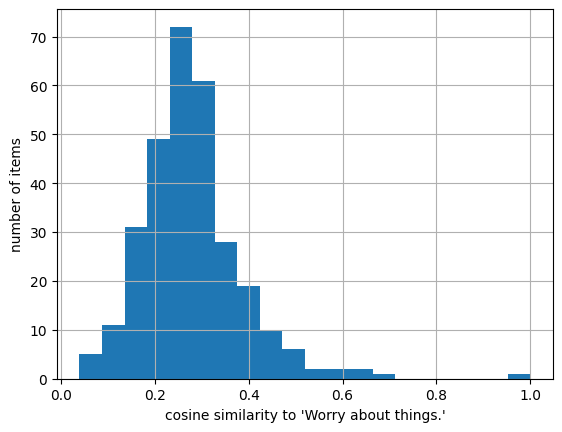

In [4]:
anchor = "Worry about things."

print(predicted_sims[anchor].sort_values(ascending=False).head(8).round(2).to_string())

predicted_sims[anchor].hist(bins=20)
plt.xlabel(f"cosine similarity to '{anchor}'"); plt.ylabel("number of items");

**Task 1.** Change `anchor` to another item (copy one from the table in 2.1). Do the nearest neighbours make psychological sense? Is the distribution of similarities wide or narrow?

### 2.3 Compare with what participants actually do

The model's similarities are *predictions*. The ground truth is how people answer: items that measure the same thing should correlate across respondents. The file below contains the observed correlation between every pair of items, computed from participant responses.

We reshape it into a matrix with the same layout as `predicted_sims`, align the two, flatten the upper triangle of each into a vector, and correlate them.

In [5]:
observed_sims = pd.read_csv(DATA + "item_corrs.csv")
observed_sims = observed_sims.pivot(index="text_i", columns="text_j", values="cor")

# Make sure rows and columns are in the same order in both matrices
predicted_aligned, observed_aligned = predicted_sims.align(observed_sims)

def upper_triangle(df):
    # Flatten the upper triangle (excluding the diagonal) into a Series
    rows, cols = np.triu_indices(len(df), k=1)
    return pd.Series(df.values[rows, cols])

pred_flat, obs_flat = upper_triangle(predicted_aligned), upper_triangle(observed_aligned)

print(f"r(predicted, observed)                 = {pred_flat.corr(obs_flat):.2f}")
print(f"r(|predicted|, |observed|)             = {pred_flat.abs().corr(obs_flat.abs()):.2f}")

r(predicted, observed)                 = 0.18
r(|predicted|, |observed|)             = 0.33


With the small general-purpose model the raw correlation is about .18 and about .33 on absolute values. We take absolute values because an item can be keyed in either direction: *"Worry about things"* and *"Am relaxed most of the time"* are strongly *negatively* correlated in people, but the model only sees that both are about anxiety.

**Discussion.** The model clearly captures something, but far from everything. What are the candidate explanations? Think about what the model was trained on, what "similar" means to it versus to a psychometrician, and reverse-keyed items.

### 2.3b Is that correlation real? A permutation test

A correlation of .33 across 44,850 item pairs is not going to be a fluke, but it is worth seeing *why* with a test that needs no distributional assumptions. If we shuffle which item is which in the observed matrix, the model's similarities no longer line up with the right correlations. Doing that a thousand times gives the distribution of correlations that would arise by chance.

Largest r under the null in 1000 permutations: 0.049
Permutation p-value: 0.000


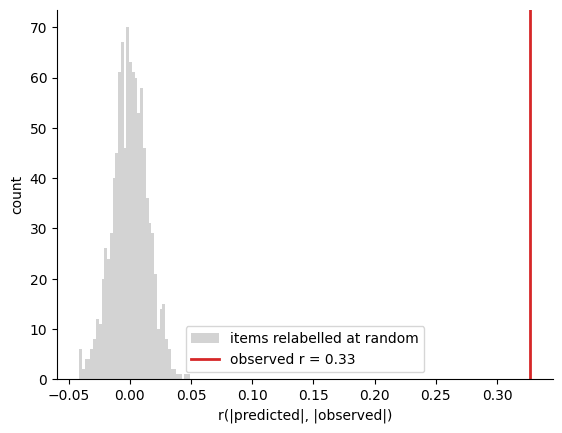

In [6]:
def permutation_null(predicted, observed, n_perm=1000, seed=0):
    """Relabel the items in the observed matrix at random and recompute r(|predicted|, |observed|)."""
    rng = np.random.default_rng(seed)
    rows, cols = np.triu_indices(len(observed), k=1)
    pred_flat = np.abs(predicted.values[rows, cols])
    obs_values = np.abs(observed.values)
    null = np.empty(n_perm)
    for i in range(n_perm):
        p = rng.permutation(len(observed))
        null[i] = np.corrcoef(pred_flat, obs_values[np.ix_(p, p)][rows, cols])[0, 1]
    return null

observed_r = pred_flat.abs().corr(obs_flat.abs())
null_r = permutation_null(predicted_aligned, observed_aligned)

plt.hist(null_r, bins=40, color="lightgrey", label="items relabelled at random")
plt.axvline(observed_r, color="C3", linewidth=2, label=f"observed r = {observed_r:.2f}")
plt.xlabel("r(|predicted|, |observed|)"); plt.ylabel("count"); plt.legend(); sns.despine()
print(f"Largest r under the null in {len(null_r)} permutations: {null_r.max():.3f}")
print(f"Permutation p-value: {(null_r >= observed_r).mean():.3f}")

### 2.3c The model knows the topic, not the direction

Why is the correlation on *absolute* values so much higher than on raw values? Chapter 1 showed that *I am happy* and *I am not happy* get nearly the same embedding. The cell below lists item pairs that the model finds very similar but that correlate **negatively** in participants' answers.

Similar according to the model, opposite according to participants:
                                  item_i                                  item_j  predicted  observed
            Can handle complex problems.         Like to solve complex problems.       0.77     -0.55
         Feel comfortable around people.           Feel comfortable with myself.       0.75     -0.40
                     Act wild and crazy.                        Do crazy things.       0.74     -0.75
  Am afraid to draw attention to myself. Don't like to draw attention to myself.       0.73     -0.66
         Feel comfortable around people.     Only feel comfortable with friends.       0.72     -0.50
   Find it difficult to approach others.                     Try to lead others.       0.64     -0.34
 Often feel uncomfortable around others.     Only feel comfortable with friends.       0.63     -0.48
 Don't like to draw attention to myself.    Make myself the center of attention.       0.63     -0.63
Am comfortable

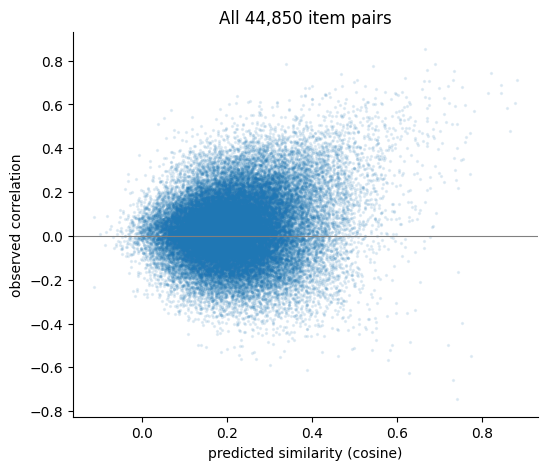

In [7]:
rows, cols = np.triu_indices(len(predicted_aligned), k=1)
pairs = pd.DataFrame({
    "item_i": predicted_aligned.index[rows],
    "item_j": predicted_aligned.columns[cols],
    "predicted": predicted_aligned.values[rows, cols],
    "observed": observed_aligned.values[rows, cols],
})

print("Similar according to the model, opposite according to participants:")
print(pairs.query("observed < -0.3").sort_values("predicted", ascending=False).head(10).round(2).to_string(index=False))

plt.figure(figsize=(6, 5))
plt.scatter(pairs["predicted"], pairs["observed"], s=2, alpha=0.1)
plt.axhline(0, color="grey", linewidth=0.8)
plt.xlabel("predicted similarity (cosine)"); plt.ylabel("observed correlation"); sns.despine()
plt.title("All 44,850 item pairs");

The scatter is a wedge: high predicted similarity goes with a *large* observed correlation in either direction. The embedding tells you that two items measure the same thing, not which way they are keyed. For scale construction that is often exactly what you want. For predicting the sign of a correlation, you need to add the keying yourself, or fine-tune the model as in the punchline below.

**Task 2.** Find the pair with the most negative observed correlation (`pairs.sort_values("observed").head()`). What does the model say about it?

### 2.4 Map the items in two dimensions

384 dimensions are hard to look at. PaCMAP compresses the item embeddings to 2D while trying to keep neighbours together. Colouring by Big Five factor shows whether the model's geometry lines up with the factor structure.

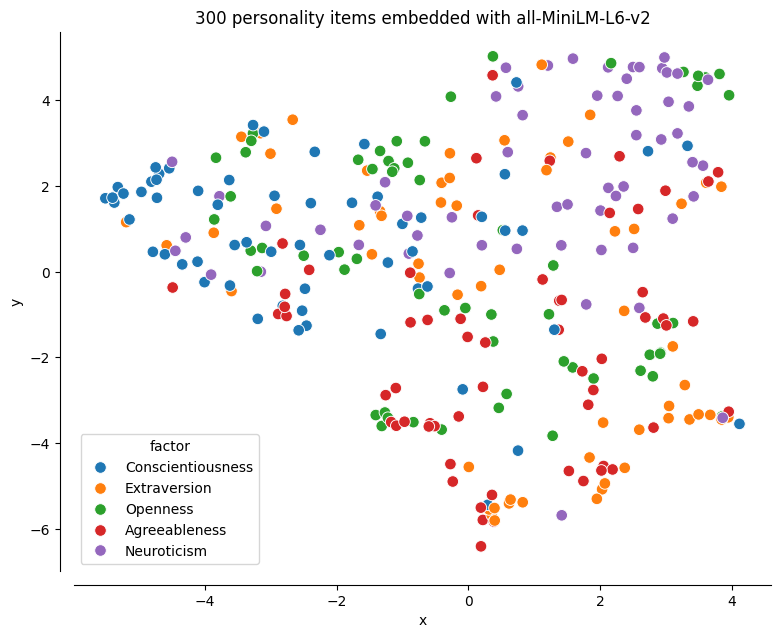

In [8]:
from pacmap import PaCMAP

pac = PaCMAP(n_components=2, random_state=42)
xy = pac.fit_transform(item_features.values)

map_df = pd.DataFrame(xy, columns=["x", "y"])
map_df["factor"] = personality["factor"].values
map_df["item"] = personality["item"].values

plt.figure(figsize=(9, 7))
sns.scatterplot(data=map_df, x="x", y="y", hue="factor", s=70)
sns.despine(offset=10)
plt.title(f"300 personality items embedded with {MODEL_NAME}");

**Task 3.** Which factors form tight clusters and which are scattered? Pick a region where two factors overlap and print the items there, for example `map_df[(map_df.x > 5) & (map_df.y < 0)]`. Can *you* tell them apart?

### Optional: the same map with hover labels

The static map hides the item text. The interactive version below shows each item when you hover over it, and lets you switch factors on and off by clicking the legend.

In [9]:
import plotly.express as px
import plotly.io as pio
if "google.colab" not in sys.modules:
    pio.renderers.default = "notebook_connected"

fig = px.scatter(map_df, x="x", y="y", color="factor", hover_name="item",
                 hover_data={"x": False, "y": False, "factor": False},
                 title=f"300 personality items embedded with {MODEL_NAME}", width=800, height=600)
fig.update_traces(marker=dict(size=7, opacity=0.8))
fig.show()

### 2.5 Can the model recover the construct from the item text?

A harder test. We embed the *names* of the 30 facets (*"Anxiety"*, *"Friendliness"*, ...), compute the similarity between each item and each facet name, and assign every item to its most similar facet. Chance is 1 in 30.

In [10]:
constructs = personality["construct"].unique()
construct_features = pd.DataFrame(model.encode(constructs), index=constructs)

construct_item_sims = pd.DataFrame(
    cosine_similarity(construct_features, item_features),
    index=constructs, columns=item_features.index
)

personality["predicted_construct"] = personality["item"].map(construct_item_sims.idxmax())
accuracy = (personality["construct"] == personality["predicted_construct"]).mean()
print(f"Accuracy: {accuracy:.2f}   (chance = {1/len(constructs):.2f})")

Accuracy: 0.23   (chance = 0.03)


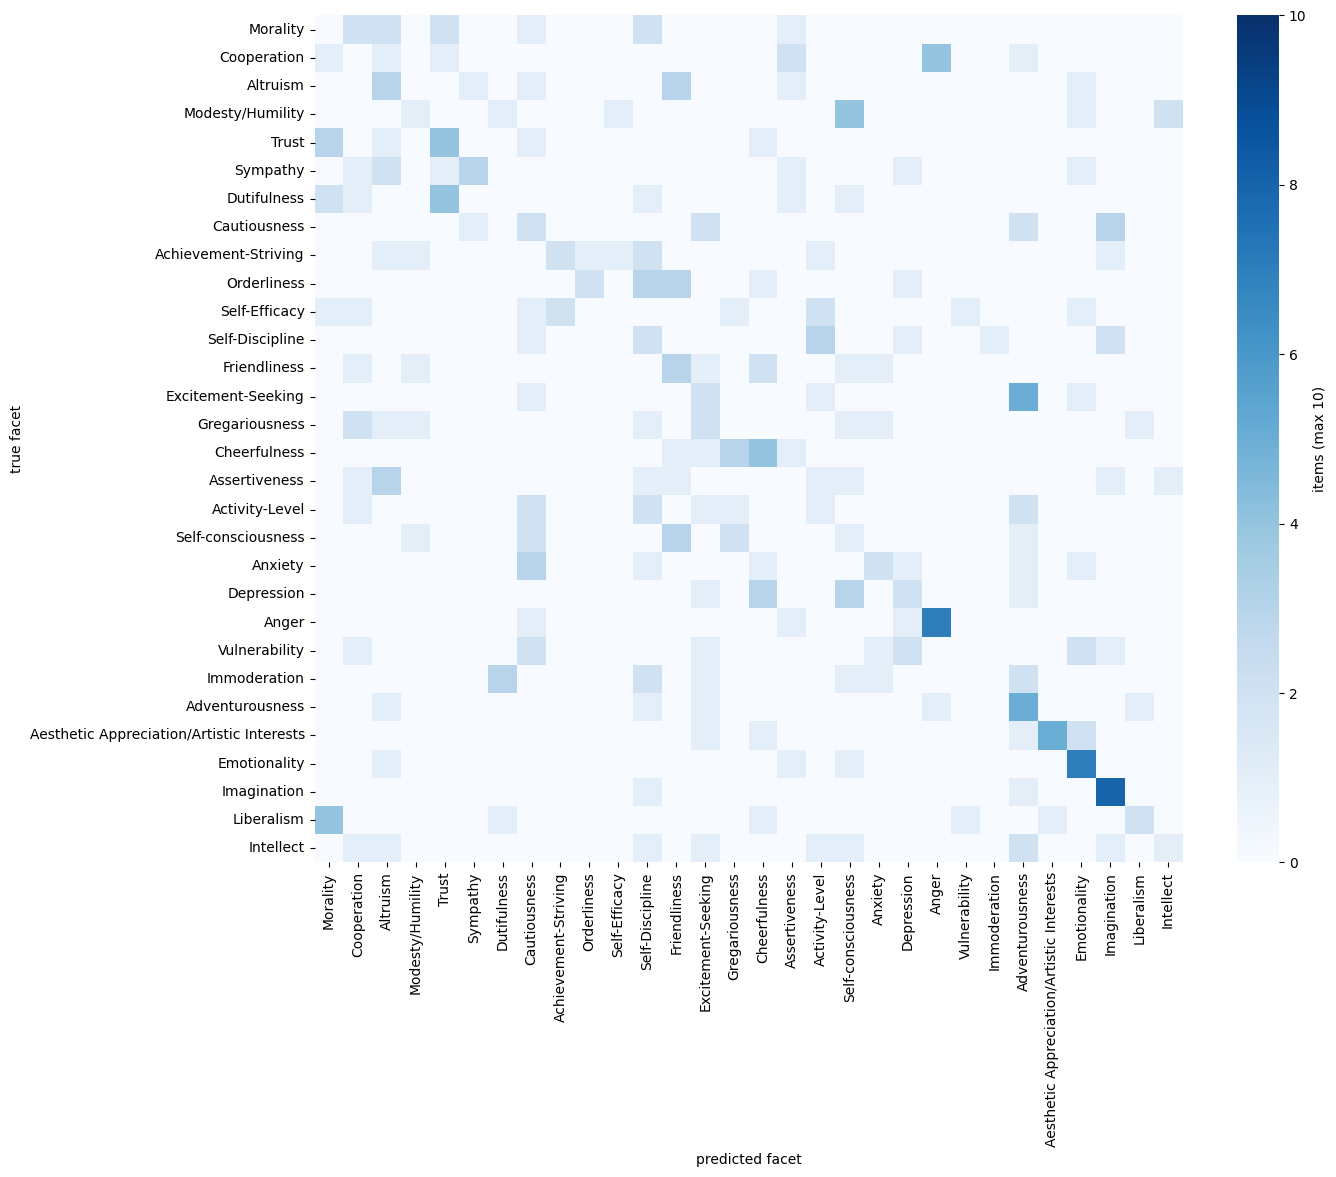

In [11]:
# Confusion matrix: rows = true facet, columns = predicted facet, ordered by factor
confusion = pd.crosstab(personality["construct"], personality["predicted_construct"])
confusion = confusion.reindex(index=constructs, columns=constructs, fill_value=0)
order = personality.sort_values("factor")["construct"].unique()
confusion = confusion.loc[order, order]

fig, ax = plt.subplots(figsize=(14, 11))
sns.heatmap(confusion, cmap="Blues", vmin=0, vmax=10, ax=ax, cbar_kws={"label": "items (max 10)"})
ax.set_xlabel("predicted facet"); ax.set_ylabel("true facet");

Some facets (often *Emotionality* and *Imagination*) are recovered well, most are not. Two readings are possible: the general-purpose model does not understand the constructs well enough, or the constructs are less distinct than the questionnaire implies. Both are interesting for a psychologist.

### 2.6 Write your own item

Now the model meets an item it has never seen. Type one you make up, run the cell, and see which existing items and which facet it lands next to.

In [12]:
my_item = "Love trying food I have never eaten before."   # <- replace with an item of your own

my_vec = model.encode([my_item])
nearest_items = pd.Series(cosine_similarity(my_vec, item_features)[0], index=item_features.index)
nearest_facets = pd.Series(cosine_similarity(my_vec, construct_features)[0], index=constructs)

print("Closest existing items:")
print(nearest_items.sort_values(ascending=False).head(5).round(2).to_string())
print("\nClosest facets:")
print(nearest_facets.sort_values(ascending=False).head(3).round(2).to_string())
top_facet = nearest_facets.idxmax()
print("\nFactor of the closest facet:", personality.loc[personality["construct"] == top_facet, "factor"].iloc[0])

Closest existing items:
item
Love to eat.                       0.70
Dislike new foods.                 0.52
Am able to control my cravings.    0.49
Willing to try anything once.      0.43
Love to help others.               0.37

Closest facets:
Adventurousness       0.32
Gregariousness        0.25
Excitement-Seeking    0.22

Factor of the closest facet: Openness


**Task 4.** Write three items: one that clearly belongs to a facet, one that is reverse-keyed (*Rarely worry about anything*), and one that mixes two facets. Does the model place each where you would? Compare with your neighbour's items.

### Optional: is the facet accuracy above chance?

The accuracy in 2.5 looks low. The same permutation logic as in 2.3b tells you how low *chance* would be with 30 facets of unequal recoverability: shuffle the true facet labels and recompute.

Chance accuracy: mean 0.034, max 0.067


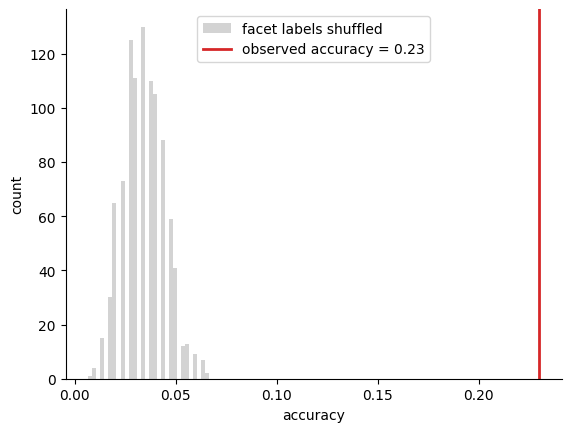

In [13]:
rng = np.random.default_rng(0)
true_facets = personality["construct"].values
predicted_facets = personality["predicted_construct"].values
null_accuracy = np.array([(rng.permutation(true_facets) == predicted_facets).mean() for _ in range(1000)])

plt.hist(null_accuracy, bins=30, color="lightgrey", label="facet labels shuffled")
plt.axvline(accuracy, color="C3", linewidth=2, label=f"observed accuracy = {accuracy:.2f}")
plt.xlabel("accuracy"); plt.ylabel("count"); plt.legend(); sns.despine()
print(f"Chance accuracy: mean {null_accuracy.mean():.3f}, max {null_accuracy.max():.3f}")

### 2.7 The punchline: a model fine-tuned on items

**Task 5 (the punchline).** Go back to the Setup cell, change `MODEL_NAME` to `"dwulff/mpnet-personality"`, and rerun the whole notebook (`Runtime -> Run all`). This model was *fine-tuned* on pairs of personality items to predict their observed correlations. Watch the correlation in 2.3, the map in 2.4 and the accuracy in 2.5 change.

```{admonition} Caveat to discuss
:class: warning
That model was fine-tuned on the same items we are evaluating it on. Why is that an unfair advantage, and what would a fair test look like?
```